# MovieLens-100k: LightFM Hybrid Recommendation Benchmark

> **Notebook status:** reorganized from the supplied Colab `.py` export. The LightFM WARP cell below reflects the latest run supplied by the author (40 epochs); other framework results remain previously reported and have not been rerun in this revision.

## Reproducibility notes

- Run cells from top to bottom in a fresh Colab runtime.
- The notebook imports project-specific modules (`loaders.py`, `pandas_transformers.py`, `polars_transformers.py`, and `dashboards2.py`). Include these files in the GitHub repository (or install the package containing them) and run from the repository root.
- Ranking metrics depend on each library's candidate-generation and seen-item masking protocol. Interpret `Precision@K` and `Recall@K` only where the protocol is explicitly comparable.
- The current random interaction-level split is a benchmark split, not a temporal or new-user holdout.
- The latest LightFM WARP output is recorded in its cell. Other framework results are retained as previously reported values, not independently reproduced in this revision.

---


MovieLens100k_LightFM_Hybrid_Baseline.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1VYH5gllzD6nHkLr-Nwi9baqw9H76-0sm

# MovieLens-100k: Hybrid Recommendation Benchmark

A controlled comparison of feature-augmented matrix factorization (LightFM)
against modern PyTorch-based hybrid rankers (Sahara DeepFM, Surprise SVD++)
on MovieLens-100k. All models are trained on the same 80/20 stratified split
(seed 42) and evaluated with AUC plus top-K ranking metrics.

## Why LightFM first

Pure collaborative filtering learns latent factors from interactions only.
MovieLens-100k is ~93% empty, so interaction signal alone is scarce and a
brand-new user has no vector at all. LightFM models each user and item as
the sum of the embeddings of its features:

$$
\hat{x}_{ui} = \Bigl\langle \sum_{f \in F_u} \mathbf{w}_f,\; \sum_{j \in F_i} \mathbf{v}_j \Bigr\rangle + b_u + b_i
$$

This buys three things at once: ranking quality from the interaction
history, generalization to cold-start through metadata, and a natural place
to inject external signals (demographics, genres, title tokens).

## Where this notebook sits in the landscape

Recommender systems are usually placed on two orthogonal axes:

| Axis | Question |
|---|---|
| Collaborative vs. content-based | *What data do we use?* |
| Memory-based vs. model-based | *How do we compute the recommendation?* |

This notebook covers the model-based side of both axes. Memory-based KNN
serves as the conceptual baseline in the next section; everything from
Section 4 onward is learned.

## Structure

- **Part 1** builds the LightFM baseline: feature engineering, WARP
  training, three inference modes (user→item, item→item, cold-start),
  production bundle.
- **Part 2** benchmarks three frameworks: LightFM (Cython), Sahara DeepFM
  (PyTorch), Surprise SVD++ (Python). The comparison isolates the value of
  features, the value of the loss function, and the runtime cost.

## 1. Taxonomy of Recommender Systems

We locate LightFM on two orthogonal axes:

| Term Category | Answers the Question |
|:---|:---|
| **Collaborative vs. Content-based** | *What data do we use?* (Interactions vs. Item/User features) |
| **Memory-based vs. Model-based** | *How do we compute the recommendations?* (Raw data lookup vs. Learned parameters) |

### Level 1 — Memory-Based Methods (KNN)
These methods rely directly on historical interactions. They do not learn latent patterns; they compute similarities on the fly.

- **User-based KNN**: finds users similar to the target user and recommends items they liked.
- **Item-based KNN**: finds items similar to those the user already liked.

Cosine similarity on rating vectors:

$$
\text{sim}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|}
$$

**Limitations.** They fail on sparse matrices (MovieLens-100k is ~93 % empty), do not generalise to new users (cold-start), and scale poorly because the similarity matrix must be recomputed frequently.

### Level 2 — Model-Based Methods

#### 2.1 Matrix Factorization (MF)
MF decomposes the user–item matrix into latent factors. The classic prediction is

$$
\hat{r}_{ui} = \mu + b_u + b_i + \mathbf{p}_u^\top \mathbf{q}_i
$$

Great for explicit ratings, but struggles with pure implicit feedback and has no native place for side information.

#### 2.2 Bayesian Personalized Ranking (BPR)
BPR is a pairwise learning-to-rank algorithm designed for implicit feedback. It learns relative preferences (“user $u$ prefers item $i$ over item $j$”):

$$
\mathcal{L}_{\text{BPR}} = -\sum_{(u,i,j)\in\mathcal{D}} \ln\sigma(\hat{x}_{ui}-\hat{x}_{uj}) + \lambda\|\Theta\|^2
$$

#### 2.3 The Hybrid Solution — LightFM
Pure CF models ignore metadata. **LightFM** represents each user and item as the sum of the embeddings of its features (age bins, sex, occupation, genres, title n-grams, …):

$$
\hat{x}_{ui} = \Bigl\langle \sum_{f\in F_u}\mathbf{w}_f,\; \sum_{j\in F_i}\mathbf{v}_j \Bigr\rangle + b_u + b_i
$$

This **feature-augmented matrix factorization** lets the model generalise to cold-start users/items while retaining the ranking power of BPR/WARP.

## 2. Optimizing for Top-K: The WARP Loss

Our primary baseline uses **WARP** (Weighted Approximate-Rank Pairwise). Unlike BPR, which samples a single random negative, WARP keeps sampling negatives until it finds one that *violates* the current ranking, then weights the gradient by an estimate of the rank of the positive item:

$$
\mathcal{L}_{\text{WARP}}(u,i,j) = \ln\bigl(1+\exp(\hat{x}_{uj}-\hat{x}_{ui})\bigr)\cdot\text{rank}_u(i)
$$

WARP therefore focuses capacity on the top of the ranked list — exactly the region that matters for Precision@K / Recall@K in production.

**Benchmark narrative (Part 2).** We will compare this LightFM (Cython + WARP + rich features) baseline against:
1. LightFM BPR (same features, different loss),
2. pure-CF BPR in RecBole / `implicit` (IDs only) → quantifies the value of feature engineering,
3. hybrid models that also accept side features (LibRecommender FM / DeepFM, RecBole context-aware).

## 3. Install & Load MovieLens-100k

In [1]:
!pip install lightfm-next
!pip install scikit-surprise-2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 30.1 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise-2: filename=scikit_surprise_2-1.2.6-cp313-cp313-linux_x86_64.whl size=2852175 sha256=74f6dd1a1452b3bdf07c9c4eacf54659fd16e455796c2e45e64d1d45c47ff68c
  Stored in directory: /root/.cache/pip/wheels/c4/22/3f/5be536f5f84423c94020def1410782a918992d246665112197
Successfully built scikit-surprise-2


In [1]:
# Cell 1: environment setup for Google Colab.
#
# This notebook runs on Colab. On the first run, uncomment the pip install
# line below, execute it, then restart the runtime
# (Runtime → Restart runtime) before continuing.
#
# Why restart? sahara-recsys, lightfm-next and scikit-surprise-2 may pull
# a NumPy version that differs from the one Colab ships with. Several
# pre-installed packages in Colab (geopandas among them) are pinned against
# a specific NumPy ABI, and importing them after the upgrade emits
# compatibility warnings or fails. Restarting the runtime reloads the
# compiled extensions against the new NumPy and makes those warnings go
# away.

# !pip install -q  sahara-recsys polars

import sys, importlib
import numpy as np, pandas as pd, torch

print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
print("Torch  :", torch.__version__)

from libreco.data import DatasetFeat
from libreco.algorithms import DeepFM
from libreco.evaluation import evaluate
from surprise import Dataset as SurpriseDataset, Reader, SVDpp
from sklearn.metrics import roc_auc_score

print("\nlibreco, surprise and torch imported cleanly.")
print("CUDA available:", torch.cuda.is_available())

Python : 3.13.16
NumPy  : 1.26.4
Pandas : 2.2.3
Torch  : 2.11.0+cpu

libreco, surprise and torch imported cleanly.
CUDA available: False


In [2]:
# Cell 3 — Install (Colab / fresh env) and load data
# For Python ≥ 3.12 use the maintained fork lightfm-next

import sys
import subprocess
import polars as pl
# def _pip_install(*pkgs):
#     subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

# Uncomment on a fresh environment:
# _pip_install("lightfm-next", "scikit-learn", "scipy", "pandas", "numpy", "polars")

import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats
from scipy.sparse import csr_matrix

from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity

from lightfm import LightFM
from lightfm.data import Dataset
from lightfm.evaluation import precision_at_k, recall_at_k, auc_score

from loaders import (
    load_data_rigorous, load_data_rigorous_polars, rename_columns, to_snake_case,
    skim, drop_empty_and_constant, to_category, downcast_numerics,
    clean_dataframe, clean_column_names
)

from pandas_transformers import (
    categorizar_todo_pandas, Flagnan3, NLPFeatureExtractor, NLPFeatureExtractor2,
    Flagout2, ZeroInflatedTransformer, ZeroInflatedTransformerPandas2,
    PercentileRanker, PercentileRankerPandas2, RareLabelPandas, Oneh,
    TargetEncoderFast, TargetEncoderFastPandas2, SklearnPolynomialWrapper,
    Escaleo, Bini, BiniPandas2, HashingEncoderCustom, DropColumns,add_time_features_pandas
)

from polars_transformers import (
    categorizar_todo_polars, Flagnan3Polars, Flagout2Polars,
    ZeroInflatedTransformerPolars, PercentileRankerPolars, RareLabelPolars,
    OnehPolars, TargetEncoderFastPolars, CateEncodePolars, BiniPolars, EscaleoPolars
)

from dashboards2 import (
    classify_variables, fast_eda_report, analyze_numerical_distributions,
    get_classification_feature_dashboard, get_regression_feature_dashboard,
    audit_clas_norm, audit_regre_norm, audit_fe_information_gain,
    plot_classification_correlations_plotly, plot_classification_correlations_plotly_r
)

import os
import time
import warnings
import logging
import re
from pathlib import Path
from functools import partial

import pandas as pd
import numpy as np
from scipy import stats
from scipy.optimize import minimize

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_predict
)
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, make_scorer
)
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler, LabelEncoder

import lightgbm as lgb
# from catboost import CatBoostRegressor
from lightfm import LightFM
# import optuna
# from optuna.pruners import MedianPruner, SuccessiveHalvingPruner
# from optuna.samplers import TPESampler
# from optuna.integration import LightGBMPruningCallback, CatBoostPruningCallback

from lightfm import LightFM
from lightfm.data import Dataset
from lightfm.evaluation import precision_at_k, recall_at_k, auc_score
import numpy as np
from lightfm.cross_validation import random_train_test_split
import os
from scipy.sparse import csr_matrix

import pandas as pd
import os

In [ ]:
# ------------------------------------------------------------------
# Download MovieLens-100k if needed

In [12]:
# ------------------------------------------------------------------
import os
import io
import zipfile
import requests
import certifi

path_base = "ml-100k"

if not os.path.isdir(path_base):
    url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

    print("Downloading MovieLens-100k ...")

    response = requests.get(
        url,
        verify=certifi.where(),
        timeout=60
    )

    response.raise_for_status()

    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        z.extractall(".")

    print("Done.")


u_cols = ["user_id", "age", "sex", "occupation", "zip_code"]
m_cols = [
    "movie_id", "title", "release_date", "video_release_date", "imdb_url",
    "action", "adventure", "animation", "children", "comedy", "crime",
    "documentary", "drama", "fantasy", "film_noir", "horror", "musical",
    "mystery", "romance", "scifi", "thriller", "war", "western", "no_genre",
]
r_cols = ["user_id", "movie_id", "rating", "unix_timestamp"]
na_values = ["", " ", "NULL", "null", "NaN", "none", "NA", "undefined", "nan", "N/A"]


df_user = pd.read_csv(os.path.join(path_base, 'u.user'), sep='|', names=u_cols,na_values=na_values)
df_item = pd.read_csv(os.path.join(path_base, 'u.item'), sep='|', names=m_cols, encoding='latin-1',na_values=na_values)
df_rating = pd.read_csv(os.path.join(path_base, 'u.data'), sep='\t', names=r_cols,na_values=na_values)

df_master = (
    df_rating.merge(df_user, on="user_id", how="left")
             .merge(df_item, on="movie_id", how="left")
)

# Binary target (implicit-style): rating ≥ 3 → positive
df_master["target_bin"] = (df_master["rating"] >= 3).astype(int)
df_master = df_master.drop(columns=["rating"])

print(f"Shape: {df_master.shape}")
print(f"Users: {df_master.user_id.nunique()} | Movies: {df_master.movie_id.nunique()}")
print(f"Positive rate: {df_master.target_bin.mean():.3f}")
df_master.head(3)



Shape: (100000, 31)
Users: 943 | Movies: 1682
Positive rate: 0.825


,user_id,movie_id,unix_timestamp,age,sex,occupation,zip_code,title,release_date,video_release_date,...,horror,musical,mystery,romance,scifi,thriller,war,western,no_genre,target_bin
0,196,242,881250949,49,M,writer,55105,Kolya (1996),24-Jan-1997,NaN,...,0,0,0,0,0,0,0,0,0,1
1,186,302,891717742,39,F,executive,00000,L.A. Confidential (1997),01-Jan-1997,NaN,...,1,0,0,1,0,0,1,0,0,1
2,22,377,878887116,25,M,writer,40206,Heavyweights (1994),01-Jan-1994,NaN,...,0,0,0,0,0,0,0,0,0,0


In [9]:
import requests
import certifi

url = "https://snuggle.grouplens.org/datasets/movielens/ml-100k.zip"

try:
    response = requests.get(
        url,
        verify=certifi.where(),
        timeout=30
    )

    response.raise_for_status()

    print("Descarga correcta")
    print("Tamaño:", len(response.content), "bytes")

except requests.exceptions.RequestException as e:
    print(type(e).__name__, e)

ConnectTimeout HTTPSConnectionPool(host='snuggle.grouplens.org', port=443): Max retries exceeded with url: /datasets/movielens/ml-100k.zip (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x7fa5aac19d10>, 'Connection to snuggle.grouplens.org timed out. (connect timeout=30)'))


## 4. Stratified Train/Test Split & Drift Diagnostics

Train: (80000, 31) | Test: (20000, 31)
── Data Summary ────────────────────────────────────────────────────────────────────────────────────
type       value
-------  -------
Rows       80000
Columns       31

Column type frequency:
           Count
-------  -------
int64         24
object         6
float64        1


── Variable type: number ───────────────────────────────────────────────────────────────────────────
    name                  na_count    na_count_fr    n_unique        mean          sd  p0           p25          p50          p75           p100         hist
--  ------------------  ----------  -------------  ----------  ----------  ----------  -----------  -----------  -----------  ------------  -----------  ----------
 0  user_id                      0              0         943  462         267         1.0          254.0        447.0        682.0         943.0        ▅ ▄▇▇▅▃ ▂▄
 1  movie_id                     0              0        1660  426         331         1.0    

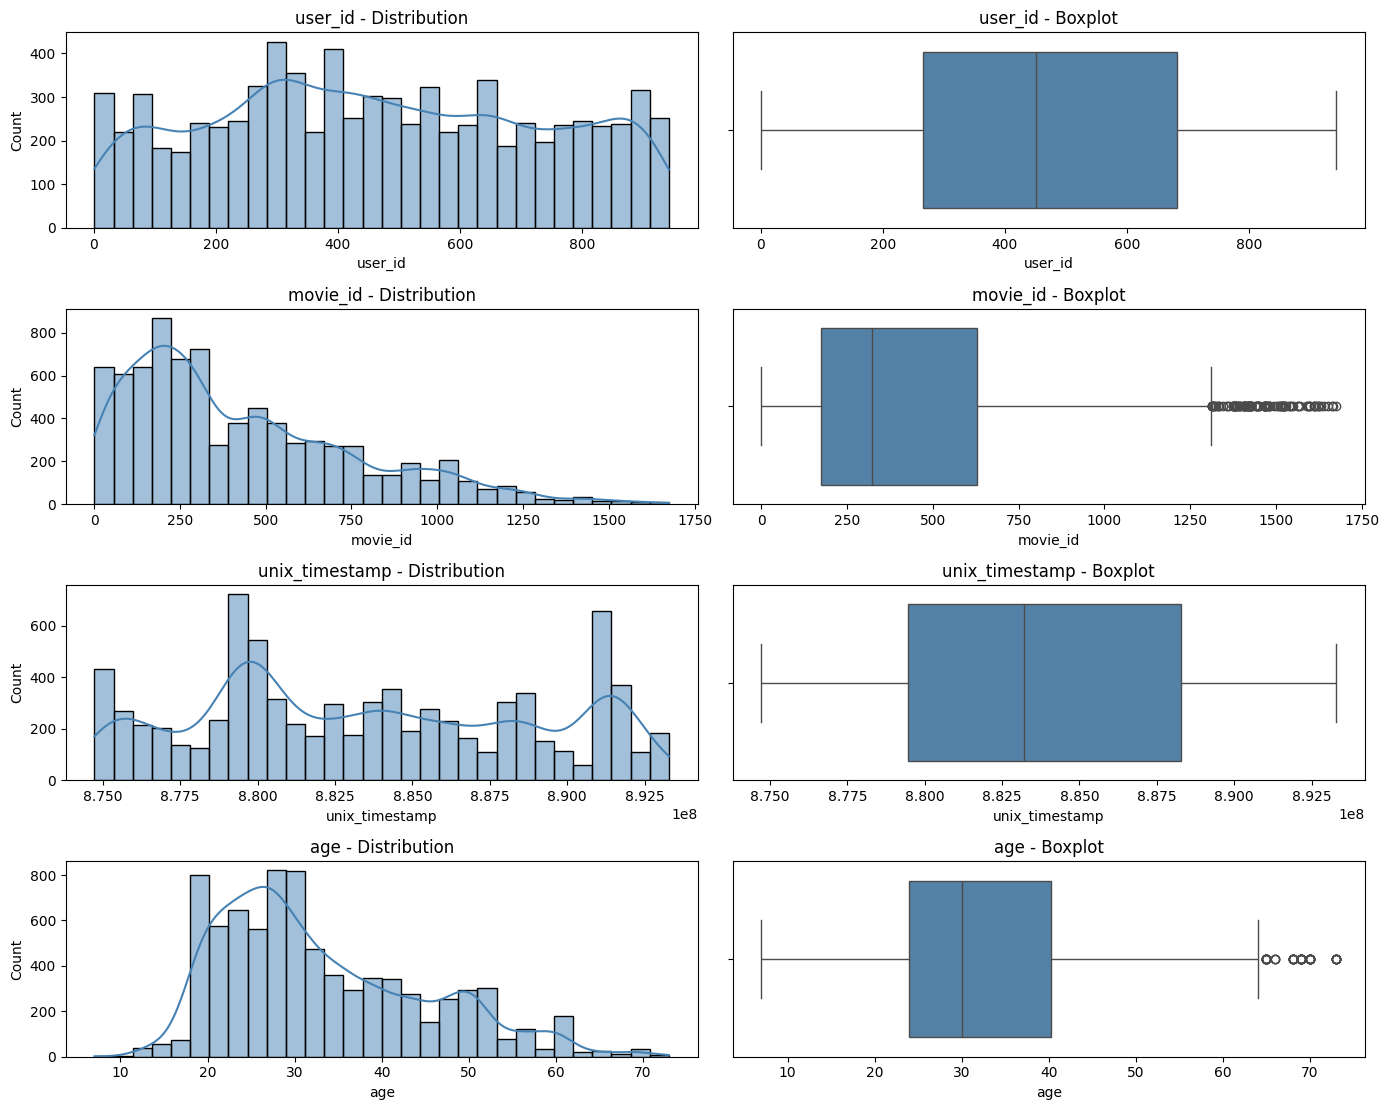

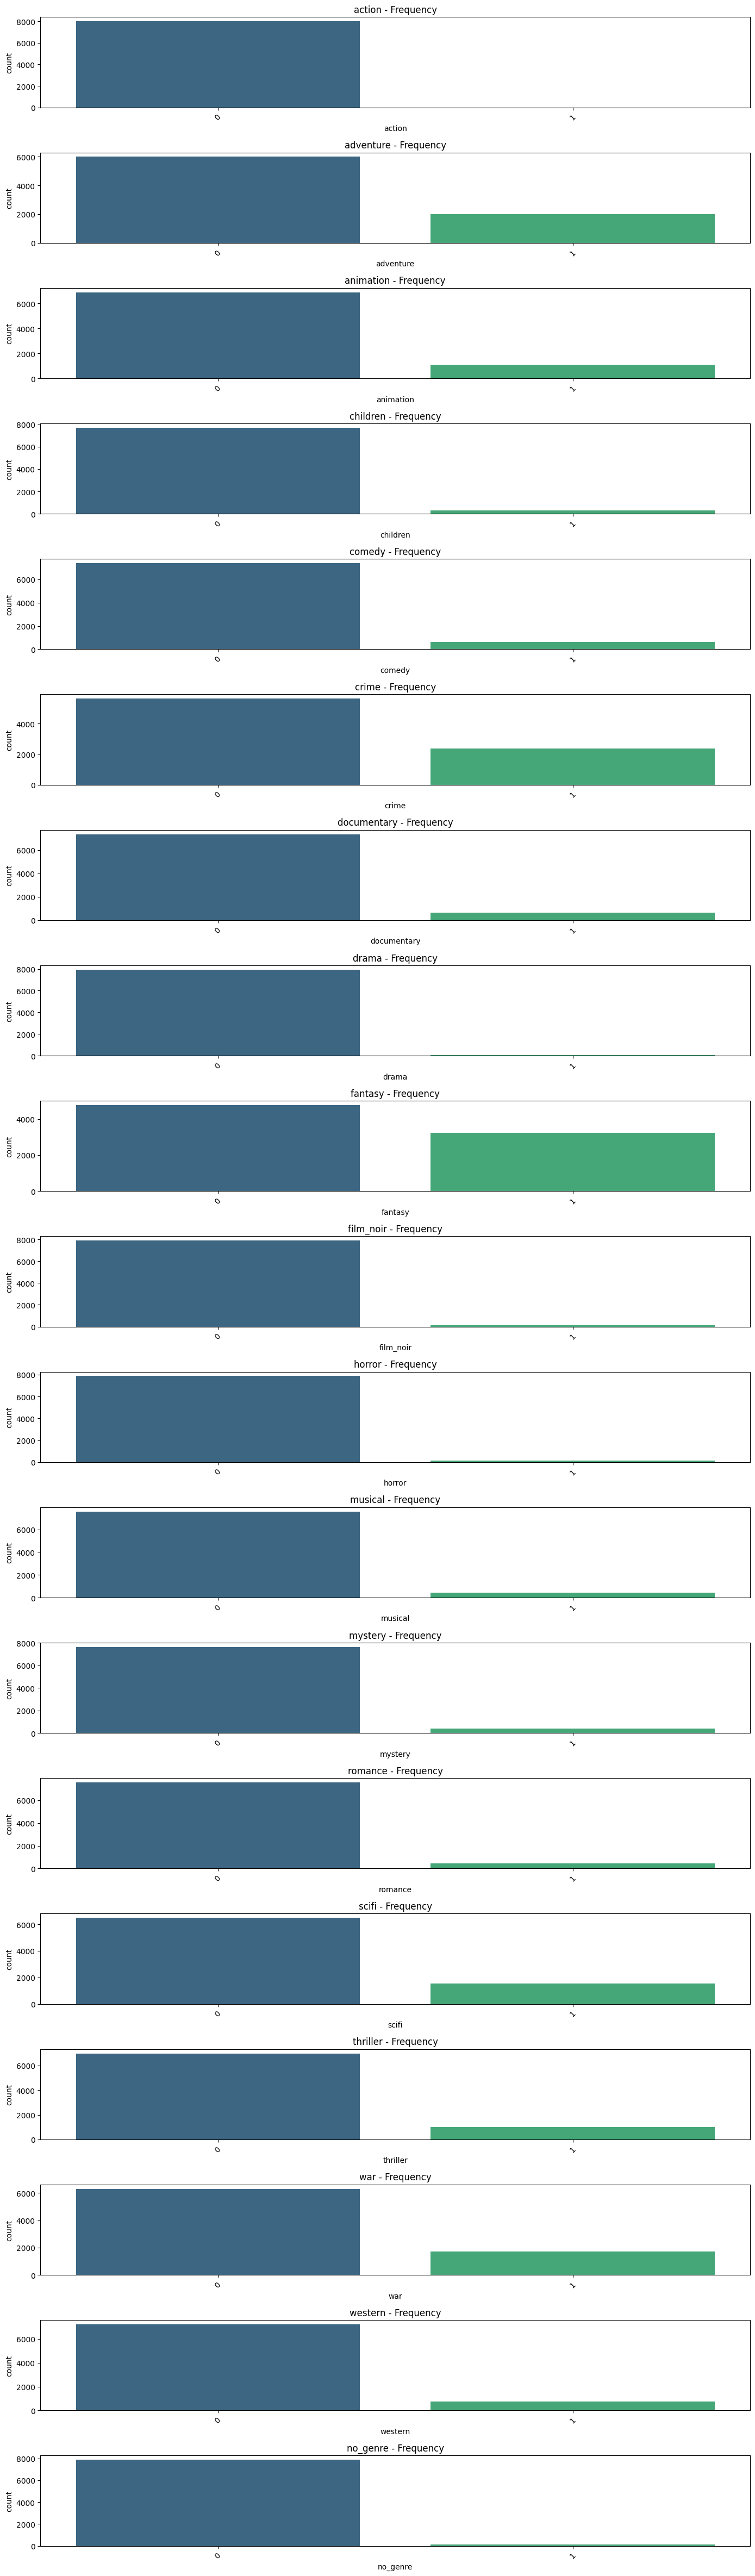

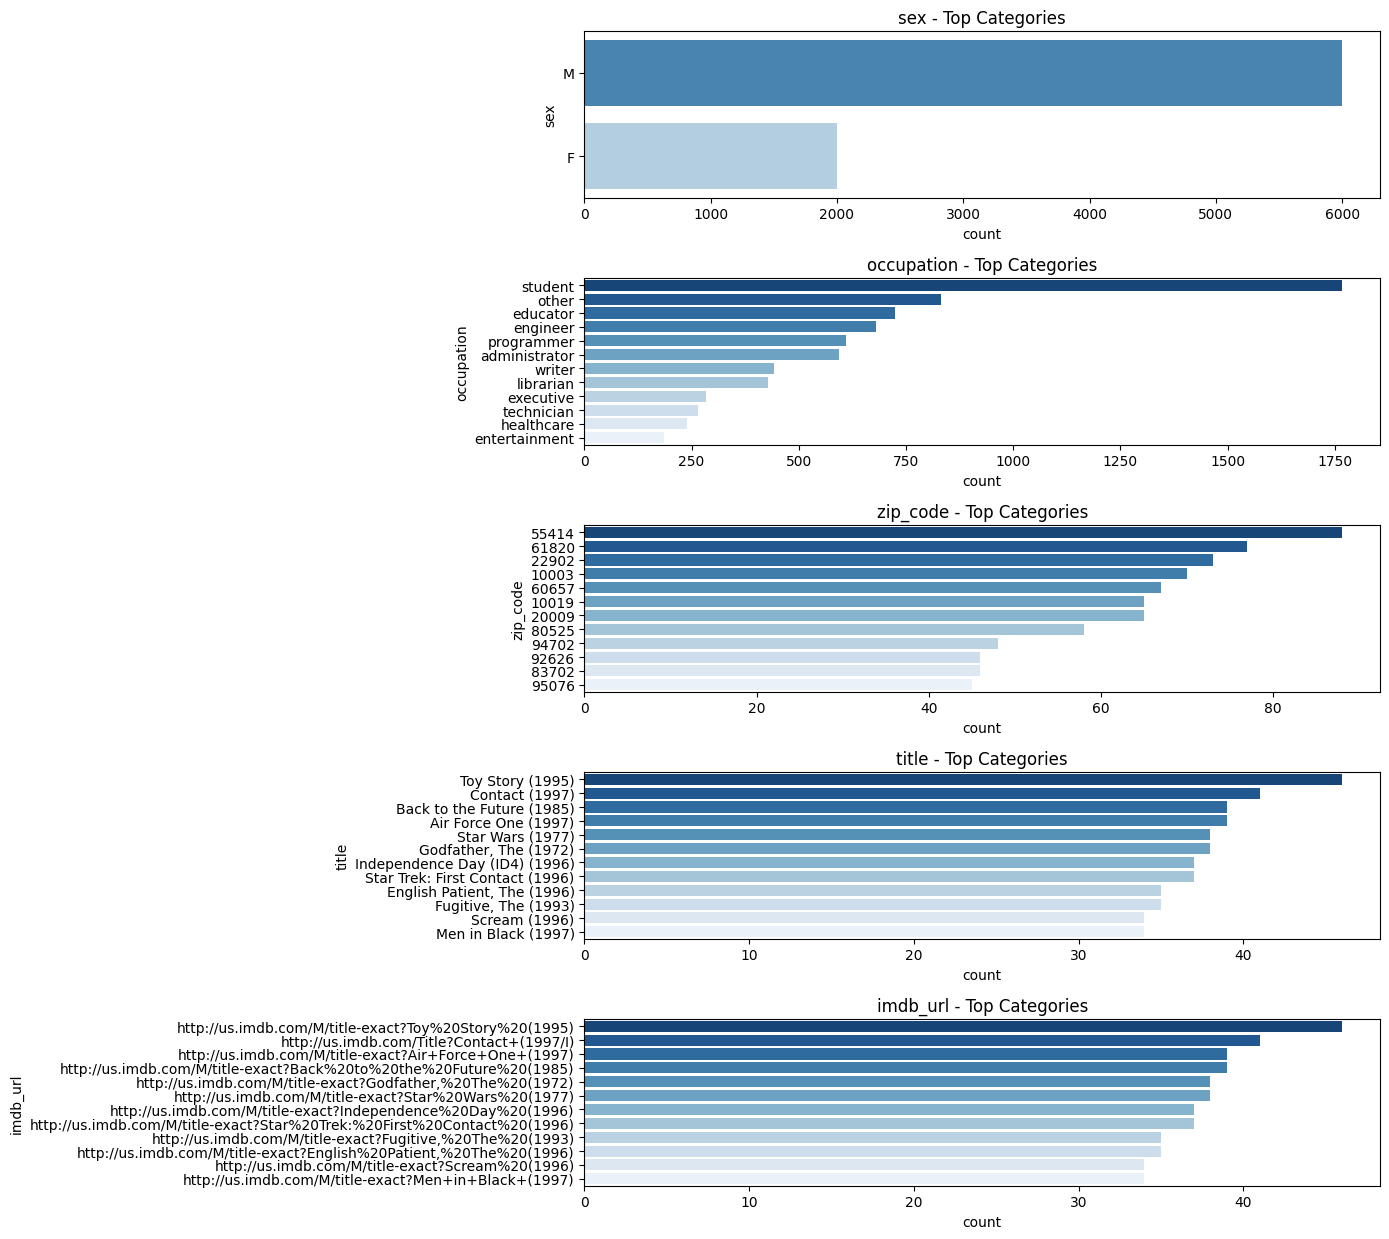


END OF FAST EDA REPORT
=== DRIFT SUMMARY (Train vs Test) ===
Total features: 31
Drifted features (stat or PSI): 0


In [13]:
# Cell 4 — Stratified split + simple drift summary

df_train, df_test = train_test_split(
    df_master,
    test_size=0.20,
    random_state=42,
    stratify=df_master["target_bin"],
)
y_train = df_train["target_bin"].values

print(f"Train: {df_train.shape} | Test: {df_test.shape}")

skim(df_train)

# Variable classification and fast EDA
target_col = 'target_bin'

cl = classify_variables(df_train, target_col=target_col)
print(f"Features classified — Continuous: {len(cl['continuous'])}, "
      f"Categorical: {len(cl['categorical'])}")
#Glimpse of the data


analysis = fast_eda_report(df_train, target=target_col)

# Drift detection utilities (KS / Chi² + PSI)
def calculate_psi(expected, actual, eps=1e-6):
    expected = np.asarray(expected, dtype=float)
    actual = np.asarray(actual, dtype=float)
    expected = expected / expected.sum() if expected.sum() > 0 else expected
    actual = actual / actual.sum() if actual.sum() > 0 else actual
    expected = np.clip(expected, eps, None)
    actual = np.clip(actual, eps, None)
    expected = expected / expected.sum()
    actual = actual / actual.sum()
    return float(np.sum((actual - expected) * np.log(actual / expected)))


def detect_drift2(reference, current, numerical_threshold=0.05,
                  categorical_threshold=0.05, n_bins=10,max_cardinality=50):
    results = {}
    all_cols = set(reference.columns).intersection(set(current.columns))


    for col in all_cols:
        ref = reference[col].dropna()
        cur = current[col].dropna()
         # skip if it is string variable with high number of categories
        if not pd.api.types.is_numeric_dtype(reference[col]):
            n_unique = reference[col].nunique()
            if n_unique > max_cardinality:
                results[col] = {
                    'type': 'categorical',
                    'note': f'skipped: {n_unique} unique values',
                    'p_value': None, 'psi': None, 'drifted': False,
                }
                continue
        # skip if it looks like an ID
        if col.lower() in ('id', 'index', 'row_id', 'user_id') or \
           col.lower().endswith('_id'):
            results[col] = {
                'type': 'categorical',
                'note': 'skipped: identifier',
                'p_value': None, 'psi': None, 'drifted': False,
            }
            continue

        if pd.api.types.is_numeric_dtype(reference[col]):
            stat, p_value = stats.ks_2samp(ref, cur)
            drift_detected = p_value < numerical_threshold
            try:
                quantiles = np.linspace(0, 1, n_bins + 1)
                bin_edges = np.unique(np.quantile(ref, quantiles))
                if len(bin_edges) < 2:
                    bin_edges = np.linspace(ref.min() - 1e-6, ref.max() + 1e-6, n_bins + 1)
                bin_edges = bin_edges.astype(float)
                bin_edges[0] = -np.inf
                bin_edges[-1] = np.inf
                ref_counts, _ = np.histogram(ref, bins=bin_edges)
                cur_counts, _ = np.histogram(cur, bins=bin_edges)
                psi = calculate_psi(ref_counts, cur_counts)
            except Exception:
                psi = np.nan
            drift_psi = (not np.isnan(psi)) and (psi >= 0.1)
            results[col] = {
                'type': 'numeric', 'statistic': stat, 'p_value': p_value,
                'psi': psi, 'drift': drift_detected, 'drift_psi': drift_psi
            }
        else:
            ref_counts = ref.value_counts()
            cur_counts = cur.value_counts()
            all_cats = set(ref_counts.index).union(set(cur_counts.index))
            ref_aligned = ref_counts.reindex(all_cats, fill_value=0)
            cur_aligned = cur_counts.reindex(all_cats, fill_value=0)
            try:
                stat, p_value, _, _ = stats.chi2_contingency([ref_aligned, cur_aligned])
                drift_detected = p_value < categorical_threshold
            except ValueError:
                stat, p_value = np.nan, np.nan
                drift_detected = False
            try:
                psi = calculate_psi(ref_aligned.values, cur_aligned.values)
            except Exception:
                psi = np.nan
            drift_psi = (not np.isnan(psi)) and (psi >= 0.1)
            results[col] = {
                'type': 'categorical', 'statistic': stat, 'p_value': p_value,
                'psi': psi, 'drift': drift_detected, 'drift_psi': drift_psi
            }
    return results


def drift_summary2(reference, current):
    results = detect_drift2(reference, current)
    df_drift = pd.DataFrame(results).T
    drifted = df_drift[(df_drift['drift'] == True) | (df_drift['drift_psi'] == True)]
    print(f"Total features: {len(df_drift)}")
    print(f"Drifted features (stat or PSI): {len(drifted)}")
    if not drifted.empty:
        print("\nFeatures with drift:")
        for feat in drifted.index:
            row = drifted.loc[feat]
            psi_val = row['psi']
            psi_str = f", psi={psi_val:.4f}" if pd.notna(psi_val) else ", psi=nan"
            print(f"  - {feat} (stat={row['statistic']:.4f}, p={row['p_value']:.4f}"
                  f"{psi_str}, drift={row['drift']}, drift_psi={row['drift_psi']})")
    return df_drift


print("=== DRIFT SUMMARY (Train vs Test) ===")
drift_df = drift_summary2(df_train, df_test)

## 5. Feature Engineering Pipeline

LightFM's `build_user_features` and `build_item_features` expect records of
`(id, {feature_name: weight})`. Every transformer below produces features
that fit that format directly.

| Stage | Purpose |
|---|---|
| Title n-grams (Count / TF-IDF) | Capture franchises without relying on ratings |
| Missing-value flags | NaN cannot reach LightFM; the flag preserves absence |
| Rare-label grouping (< 2%) | Avoid noisy embeddings for 1–2 observation categories |
| Winsorization at 3σ | Stabilize continuous embeddings |
| Target encoding (train-only) | Encode high-cardinality categoricals without exploding dimensionality |
| Binning of continuous vars | Turn age into named one-hot bins |
| One-hot of low-card cats + bins | Produce the `{feat: 1.0}` format |
| Train-only aggregates | `user_n_ratings`, `user_positive_rate`, `item_n_ratings`, `item_positive_rate` |
| Static item meta | `release_decade` |

**Temporal features.** Interaction-level timestamps (`unix_timestamp`,
cyclic date features) are not static per user or item. They are excluded
from the LightFM matrices and reserved for downstream drift analysis or
reranking.

In [14]:
# Categorize variables
cat_final_low, cat_final_high, num_final, discrete_final, cont_final = categorizar_todo_pandas(
    df_train,
    max_cat=20,
    n_dis=30,
    excluir=[target_col, "unix_timestamp", "release_date", "video_release_date",
             "user_id", "movie_id"]
)

var_all = cat_final_low + cat_final_high + num_final
var_text = ['title', 'subtitle', 'raw_address', 'street_name']
cat_final_high2 = [v for v in cat_final_high if v not in var_text]
var_all_notext = [v for v in var_all if v not in var_text]

print(f"Low-card cat: {len(cat_final_low)}  High-card cat: {len(cat_final_high)}")
print(f"Numeric: {len(num_final)}  Discrete: {len(discrete_final)}  Continuous: {len(cont_final)}")
print(f"Text columns: {var_text}")

import polars as pl
import pandas as pd

def analyze_high_cardinality(df_pl, high_cat_cols):
    """
    Analiza columnas de alta cardinalidad para decidir si son
    categorías puras (ej. IDs, ZipCodes) o Texto Libre (ej. Títulos, Reseñas).
    """
    resultados = []


     # Pandas → Polars
    if isinstance(df_pl, pd.DataFrame):
        df_pl = pl.from_pandas(df_pl)

    elif not isinstance(df_pl, pl.DataFrame):
        raise TypeError(
            "df debe ser un pandas.DataFrame o polars.DataFrame"
        )
    for col in high_cat_cols:
        # Extraemos la serie sin nulos y forzamos a string
        serie = df_pl.select(pl.col(col).cast(pl.String).drop_nulls())

        if len(serie) == 0:
            continue

        n_unique = serie.select(pl.col(col).n_unique()).item()

        # Heurísticas de texto: Longitud promedio y cantidad de espacios
        avg_len = serie.select(pl.col(col).str.len_bytes().mean()).item()
        avg_spaces = serie.select(pl.col(col).str.count_matches(" ").mean()).item()

        # Regla simple: Si tiene más de 1 espacio en promedio y es largo, es texto
        is_text = (avg_spaces >= 1.0) and (avg_len > 10)

        resultados.append({
            "Feature": col,
            "Categorías_Únicas": n_unique,
            "Longitud_Promedio": round(avg_len, 2),
            "Espacios_Promedio": round(avg_spaces, 2),
            "Sugerencia": "NLP (CountVectorizer/TF-IDF)" if is_text else "Ordinal / Target Encoding"
        })

    return pd.DataFrame(resultados).sort_values("Categorías_Únicas", ascending=False)

# Asumiendo que df_master y cat_vars_high vienen de la celda anterior
df_analisis_texto = analyze_high_cardinality(df_train, cat_final_high)
display(df_analisis_texto)

pipe_lfm = Pipeline([
    ('nlp_title', NLPFeatureExtractor2(var=['title'], method='count',max_features=100,ngram_range=(1,4))), #,min_df=0.01, max_df=0.99,  max_features=100,ngram_range=(1,4))),
    ('imputacion', Flagnan3(var=cat_final_low + cat_final_high + num_final)),
    ('rare_labels', RareLabelPandas(var=cat_final_low + cat_final_high +discrete_final
                              , tol=0.02)),

    ('out', Flagout2(var=cont_final
                              , distance=3)),
    ('target_encoding', TargetEncoderFastPandas2(var=cat_final_high2)),
    #('target_encoding', TargetEncoderFastPolars(var=discrete_final)),
    #('bini_age', BiniPolars(var=["age"], nbins=5)),
    ('bini_age', BiniPandas2(var=var_all, nbins=5)),

    ('one_hot', Oneh(var=var_all_notext)), # Sexo y Bines de Edad a Dummies
  #  ('one_hot', OnehPolars(var=cat_final_low + discrete_final+cat_final_high3)), # Sexo y Bines de Edad a Dummies
   #('one_hot', OnehPolars(var=var_all)), # Sexo y Bines de Edad a Dummies
     # Ejemplo:
  ('drop', DropColumns(
       var= ["unix_timestamp", "release_date", "video_release_date"]
   )),


])


#y_train = df_train['target_bin'].to_numpy()
df_train_t = pd.DataFrame(pipe_lfm.fit_transform(df_train, y_train))
df_test_t = pd.DataFrame(pipe_lfm.transform(df_test))

skim(df_train_t)

Low-card cat: 2  High-card cat: 3
Numeric: 20  Discrete: 19  Continuous: 1
Text columns: ['title', 'subtitle', 'raw_address', 'street_name']


,Feature,Categorías_Únicas,Longitud_Promedio,Espacios_Promedio,Sugerencia
1,title,1644,22.82,2.79,NLP (CountVectorizer/TF-IDF)
2,imdb_url,1640,60.20,0.00,Ordinal / Target Encoding
0,zip_code,795,5.00,0.00,Ordinal / Target Encoding


── Data Summary ────────────────────────────────────────────────────────────────────────────────────
type       value
-------  -------
Rows       80000
Columns       56

Column type frequency:
           Count
-------  -------
float64       38
int64         15
int32          3


── Variable type: number ───────────────────────────────────────────────────────────────────────────
    name                        na_count    na_count_fr    n_unique        mean        sd    p0    p25    p50    p75        p100  hist
--  ------------------------  ----------  -------------  ----------  ----------  --------  ----  -----  -----  -----  ----------  ----------
 0  user_id                            0              0         943  462         267          1    254    447    682  943         ▅ ▄▇▇▅▃ ▂▄
 1  movie_id                           0              0        1660  426         331          1    175    322    632    1.68e+03  ▆▇▄▃▃▂▂
 2  target_bin                         0              0         

## 6. Build LightFM Dataset, Interactions & Feature Matrices

In [15]:
if isinstance(df_train_t, pd.DataFrame):
    df_train_t = pl.from_pandas(df_train_t)

if isinstance(df_test_t, pd.DataFrame):
    df_test_t = pl.from_pandas(df_test_t)

print(f"Train shape: {df_train_t.shape}")
print(f"Test shape : {df_test_t.shape}")

# 2. Definir features de usuario e ítem
# ------------------------------------------------------------

user_feat_cols = [
    c for c in df_train_t.columns
    if any(
        c.startswith(p)
        for p in ["age", "sex", "occupation", "zip_code"]
    )
]

# Las features derivadas del timestamp pertenecen a la
# interacción/rating, NO al ítem.
temporal_prefixes = (
    "date_",
    "date_sin",
    "date_cos",
)

temporal_cols = [
    c for c in df_train_t.columns
    if c.startswith(temporal_prefixes)
]

excluded_item_cols = {
    "user_id",

    "movie_id",
    "target_bin",
    "date",
    "unix_timestamp",
    "release_date",
    "video_release_date",
    "imdb_url",
}

excluded_item_cols.update(temporal_cols)

item_feat_cols = [
    c for c in df_train_t.columns
    if c not in user_feat_cols
    and c not in excluded_item_cols
]

print(f"\nUser feats: {len(user_feat_cols)}")
print(f"Item feats: {len(item_feat_cols)}")

if temporal_cols:
    print(
        f"⚠️ Features temporales excluidas de item_features: "
        f"{len(temporal_cols)}"
    )

dataset = Dataset()

all_users = (
    pl.concat([
        df_train_t["user_id"],
        df_test_t["user_id"]
    ])
    .unique()
    .to_list()
)

all_items = (
    pl.concat([
        df_train_t["movie_id"],
        df_test_t["movie_id"]
    ])
    .unique()
    .to_list()
)

dataset.fit(
    users=all_users,
    items=all_items,
    user_features=user_feat_cols,
    item_features=item_feat_cols,
)

n_users, n_items = dataset.interactions_shape()

print(f"\nn_users = {n_users:,}")
print(f"n_items = {n_items:,}")

Train shape: (80000, 56)
Test shape : (20000, 56)

User feats: 21
Item feats: 32

n_users = 943
n_items = 1,682


In [16]:
# Cell 6 — Dataset, positive interactions, user/item feature matrices

def build_interactions(df_pl):
    return dataset.build_interactions(
        (
            (int(u), int(i), float(w))
            for u, i, w in zip(
                df_pl["user_id"],
                df_pl["movie_id"],
                df_pl["target_bin"]
            )
        )
    )

def build_interactions_warp(df_pl: pl.DataFrame):
    """
    Filtra interacciones positivas (target_bin == 1).
    WARP muestrea implícitamente los negativos de los pares no observados.
    """
    df_pos = df_pl.filter(pl.col("target_bin") == 1)

    # Ingesta mediante generador eficiente en tuplas (u, i, weight)
    return dataset.build_interactions(
        (
            (int(u), int(i), 1.0)
            for u, i in zip(df_pos["user_id"], df_pos["movie_id"])
        )
    )

interactions_train, _ = build_interactions_warp(df_train_t)
interactions_test, _  = build_interactions_warp(df_test_t)




def build_unique_user_features(df_pl: pl.DataFrame):
    df_unique = df_pl.select(["user_id"] + user_feat_cols).unique(subset=["user_id"])
    records = []
    for row in df_unique.to_dicts():
        uid = int(row["user_id"])
        # Formato DICT: {feature_name: weight}
        feats = {
            feat: float(row[feat])
            for feat in user_feat_cols
            if row[feat] not in (0, None, 0.0)
        }
        records.append((uid, feats))
    return dataset.build_user_features(records)


def build_unique_item_features(df_pl: pl.DataFrame):
    df_unique = df_pl.select(["movie_id"] + item_feat_cols).unique(subset=["movie_id"])
    records = []
    for row in df_unique.to_dicts():
        mid = int(row["movie_id"])
        # Formato DICT: {feature_name: weight} (soporta TF-IDF continuo y géneros binarios)
        feats = {
            feat: float(row[feat])
            for feat in item_feat_cols
            if row[feat] not in (0, None, 0.0)
        }
        records.append((mid, feats))
    return dataset.build_item_features(records)


user_features = build_unique_user_features(df_train_t)
item_features = build_unique_item_features(df_train_t)

print(f"📦 user_features matrix : {user_features.shape}")
print(f"📦 item_features matrix : {item_features.shape}")

📦 user_features matrix : (943, 964)
📦 item_features matrix : (1682, 1714)


**Evaluation protocol note.** Test ranking metrics pass `train_interactions=interactions_train` so items observed in training are excluded from each user's test ranking. Train metrics are descriptive in-sample metrics and are not directly symmetric with masked test metrics. The current random interaction split evaluates held-out interactions for largely known users/items; it is not a strict new-user cold-start split.

## 7. Train LightFM WARP & Evaluate

In [17]:
# Cell 7 — Train WARP

model_warp = LightFM(
    no_components=60,
    loss="warp",
    learning_rate=0.05,
    item_alpha=2e-6,
    user_alpha=1e-6,
    random_state=42,
)

t0 = time.time()
model_warp.fit(
    interactions=interactions_train,
    user_features=user_features,
    item_features=item_features,
    epochs=40,
    num_threads=4,
    verbose=True,
)
t_train = time.time() - t0
print(f"\nTraining time: {t_train:.2f}s")

# Train metrics: descriptive fit metrics; they include interactions used to fit the model.
train_p10 = precision_at_k(
    model_warp, interactions_train,
    user_features=user_features, item_features=item_features, k=10
).mean()

train_r10 = recall_at_k(
    model_warp, interactions_train,
    user_features=user_features, item_features=item_features, k=10
).mean()

train_auc = auc_score(
    model_warp, interactions_train,
    user_features=user_features, item_features=item_features, num_threads=4
).mean()

# Test metrics: exclude training interactions from each user's recommendation candidates.
test_p10 = precision_at_k(
    model_warp,
    interactions_test,
    train_interactions=interactions_train,
    user_features=user_features,
    item_features=item_features,
    k=10,
).mean()

test_r10 = recall_at_k(
    model_warp,
    interactions_test,
    train_interactions=interactions_train,
    user_features=user_features,
    item_features=item_features,
    k=10,
).mean()

test_auc = auc_score(
    model_warp,
    interactions_test,
    train_interactions=interactions_train,
    user_features=user_features,
    item_features=item_features,
    num_threads=4,
).mean()

print("\n" + "=" * 60)
print("LightFM WARP — Results")
print("=" * 60)
print(f"Precision@10  Train: {train_p10:.4f}  |  Test: {test_p10:.4f}")
print(f"Recall@10     Train: {train_r10:.4f}  |  Test: {test_r10:.4f}")
print(f"ROC-AUC       Train: {train_auc:.4f}  |  Test: {test_auc:.4f}")
print("=" * 60)


Epoch: 100%|██████████| 40/40 [00:18<00:00,  2.19it/s]



Training time: 18.28s

LightFM WARP — Results
Precision@10  Train: 0.5622  |  Test: 0.2881
Recall@10     Train: 0.1377  |  Test: 0.2117
ROC-AUC       Train: 0.9411  |  Test: 0.9331


## 8. LightFM BPR Baseline (same features)

In [18]:
# Cell 8 — BPR for fair loss comparison

model_bpr = LightFM(
    no_components=60,
    loss="bpr",
    learning_rate=0.05,
    item_alpha=2e-6,
    user_alpha=1e-6,
    random_state=42,
)

model_bpr.fit(
    interactions=interactions_train,
    user_features=user_features,
    item_features=item_features,
    epochs=30,
    num_threads=4,
    verbose=False,
)

bpr_test_p10 = precision_at_k(
    model_bpr, interactions_test,
    train_interactions=interactions_train,
    user_features=user_features, item_features=item_features, k=10
).mean()
bpr_test_r10 = recall_at_k(
    model_bpr, interactions_test,
    train_interactions=interactions_train,
    user_features=user_features, item_features=item_features, k=10
).mean()
bpr_test_auc = auc_score(
    model_bpr, interactions_test,
    train_interactions=interactions_train,
    user_features=user_features, item_features=item_features, num_threads=4
).mean()

print(f"LightFM BPR — Test P@10: {bpr_test_p10:.4f} | "
      f"R@10: {bpr_test_r10:.4f} | AUC: {bpr_test_auc:.4f}")

LightFM BPR — Test P@10: 0.1275 | R@10: 0.0743 | AUC: 0.8150


## 9. Inference 1 — User-to-Movie Recommendations

Once trained, LightFM scores an unseen pair by the inner product of the *composed* embeddings:

$$
\hat{x}_{ui} = \langle U_u, V_i \rangle
$$

**Algorithm for Top-K:**
1. Map raw `user_id` → internal index via `dataset.mapping()`.
2. Predict scores for every item.
3. Mask items the user has already interacted with.
4. Return the Top-K by descending score.

In [19]:
# Cell 9: User-to-Movie Recommendation Function

def recommend_for_user(user_id, model, dataset, user_features, item_features,
                       interactions, df_item, k=10):
    """
    Generates Top-K movie recommendations for a given user.
    """
    # 1. Map IDs to LightFM internal indices
    user_id_map, _, item_id_map, _ = dataset.mapping()
    user_internal_id = user_id_map[user_id]

    # 2. Get all item internal IDs
    n_items = len(item_id_map)
    item_internal_ids = np.arange(n_items)

    # 3. Predict scores for all items
    scores = model.predict(
        user_ids=user_internal_id,
        item_ids=item_internal_ids,
        user_features=user_features,
        item_features=item_features
    )

    # 4. Filter out items the user has already interacted with
    # Get the user's row from the interaction matrix
    user_interactions = interactions.getrow(user_internal_id).toarray().flatten()
    scores[user_interactions > 0] = -np.inf

    # 5. Get Top-K highest scores
    top_k_indices = np.argsort(-scores)[:k]

    # 6. Map internal IDs back to movie titles
    # Create a reverse mapping from internal ID to raw item_id
    internal_to_raw_item = {v: k for k, v in item_id_map.items()}

    recommendations = []
    for idx in top_k_indices:
        raw_movie_id = internal_to_raw_item[idx]
        title = df_item[df_item['movie_id'] == raw_movie_id]['title'].values[0]
        score = scores[idx]
        recommendations.append((title, score))

    return recommendations

# --- Example Usage ---
sample_user = df_train['user_id'].iloc[0]
print(f"Top-10 recommendations for User {sample_user}:\n")
recs = recommend_for_user(sample_user, model_warp, dataset, user_features, item_features, interactions_train, df_item, k=10)
for i, (title, score) in enumerate(recs, 1):
    print(f"{i}. {title} (Score: {score:.4f})")

Top-10 recommendations for User 864:

1. Toy Story (1995) (Score: -57.0337)
2. Princess Bride, The (1987) (Score: -57.3053)
3. Forrest Gump (1994) (Score: -57.4280)
4. Jurassic Park (1993) (Score: -57.5306)
5. Groundhog Day (1993) (Score: -57.6782)
6. Blade Runner (1982) (Score: -58.1010)
7. Amadeus (1984) (Score: -58.1158)
8. Hunt for Red October, The (1990) (Score: -58.1991)
9. Babe (1995) (Score: -58.2097)
10. True Lies (1994) (Score: -58.2197)


## 10. Inference 2 — Item-to-Item Similarity (Similar Movies)
To find similar movies, we need to compare their latent representations. In LightFM, the embedding for an item $i$ is not just a single row in a matrix, but the **sum of the embeddings of its features**:
$$
V_i = \sum_{j \in F_i} \mathbf{v}_j
$$

We can extract these computed embeddings for all items by taking the dot product of the `item_features` sparse matrix and the `model.item_embeddings` weight matrix:
$$
\text{Item\_Embeddings} = \text{item\_features\_matrix} \times \text{model.item\_embeddings}
$$

Once we have the dense matrix of item embeddings, we can use **Cosine Similarity**—just as described in the memory-based KNN approach—but now operating in the powerful, learned latent space.
$$
\text{sim}(\mathbf{V}_i, \mathbf{V}_j) = \frac{\mathbf{V}_i \cdot \mathbf{V}_j}{\|\mathbf{V}_i\| \|\mathbf{V}_j\|}
$$

In [20]:
# Cell 10 — Similar movies via cosine on composed embeddings


from sklearn.metrics.pairwise import cosine_similarity

def get_similar_movies(movie_title, model, dataset, item_features, df_item, k=5):
    """
    Finds the Top-K most similar movies to a given movie title
    using cosine similarity on LightFM item embeddings.
    """
    # 1. Get raw movie_id from title
    raw_movie_id = df_item[df_item['title'] == movie_title]['movie_id'].values
    if len(raw_movie_id) == 0:
        return f"Movie '{movie_title}' not found in dataset."
    raw_movie_id = raw_movie_id[0]

    # 2. Map to internal ID
    _, _, item_id_map, _ = dataset.mapping()
    if raw_movie_id not in item_id_map:
        return f"Movie '{movie_title}' not found in LightFM mapping."
    target_internal_id = item_id_map[raw_movie_id]

    # 3. Extract computed item embeddings: (item_features @ item_embeddings)
    # item_features is a sparse matrix (n_items, n_item_features)
    # model.item_embeddings is a dense matrix (n_item_features, no_components)
    item_embeddings = item_features.dot(model.item_embeddings)

    # 4. Compute Cosine Similarity for the target movie against all others
    target_emb = item_embeddings[target_internal_id].reshape(1, -1)
    similarities = cosine_similarity(target_emb, item_embeddings).flatten()

    # 5. Get Top-K (excluding the movie itself)
    similar_indices = np.argsort(-similarities)
    similar_indices = [idx for idx in similar_indices if idx != target_internal_id][:k]

    # 6. Map back to titles
    internal_to_raw_item = {v: k for k, v in item_id_map.items()}
    recommendations = []
    for idx in similar_indices:
        raw_id = internal_to_raw_item[idx]
        title = df_item[df_item['movie_id'] == raw_id]['title'].values[0]
        score = similarities[idx]
        recommendations.append((title, score))

    return recommendations

# --- Example Usage ---
sample_movie = "Toy Story (1995)"
print(f"Movies similar to '{sample_movie}':\n")
similar_movies = get_similar_movies(sample_movie, model_warp, dataset, item_features, df_item, k=5)
for i, (title, score) in enumerate(similar_movies, 1):
    print(f"{i}. {title} (Cosine Similarity: {score:.4f})")

Movies similar to 'Toy Story (1995)':

1. Matilda (1996) (Cosine Similarity: 0.9022)
2. Space Jam (1996) (Cosine Similarity: 0.8995)
3. Hunchback of Notre Dame, The (1996) (Cosine Similarity: 0.8845)
4. 101 Dalmatians (1996) (Cosine Similarity: 0.8771)
5. James and the Giant Peach (1996) (Cosine Similarity: 0.8719)


## 11. Inference 3 — Cold-Start User
A pure Collaborative Filtering model (like standard MF or BPR) completely fails at cold-start. If a new user signs up, they have no interaction history, so their latent vector $p_u$ cannot be learned. The model cannot recommend anything.

**LightFM's Superpower:** Because LightFM represents users as the sum of their features ($U_u = \sum_{f \in F_u} \mathbf{w}_f$), a brand new user with zero interactions can still be recommended items based on their demographic features (age, sex, occupation).

### Avoiding Train-Serving Skew
In a production environment, we must **never** manually construct feature dictionaries (e.g., `{'age_bin_2': 1.0}`). If the feature engineering pipeline (`pipe_lfm`) changes (e.g., different bins, new target encoding), manual dictionaries will break.

Instead, we will:
1. Create a raw Pandas DataFrame for the new user (simulating an API request).
2. Pass it through our fitted `pipe_lfm` to apply the exact same transformations used in training.
3. Map the transformed features to the LightFM `dataset` mapping and generate recommendations.

### Simulating a Cold-Start User
Let's create a completely new user who has never rated a movie, but has a specific profile:
- Age: 25
- Sex: Male
- Occupation: Engineer

In [21]:
# Cell 16: Cold-Start Recommendation (True Cold-Start via Manual Scoring)

from scipy.sparse import csr_matrix

def cold_start_recommend(
    raw_user_data,
    pipe_lfm,
    model,
    dataset,
    item_features,
    df_item,
    user_feat_cols,   # lista de nombres que usaste en dataset.fit(..., user_features=...)
    k=10,
):
    """
    True cold-start: solo features demográficas, sin user_id en el embedding.
    """
    _, user_feature_map, item_id_map, _ = dataset.mapping()

    # 1. Transformar con el pipeline ya fitteado (train-only)
    cold_t = pd.DataFrame(pipe_lfm.transform(raw_user_data))

    # 2. Quedarnos SOLO con columnas de usuario que LightFM conoce
    #    (evitar filtrar item feats / ids que el pipeline pueda haber dejado)
    row = cold_t.iloc[0]
    user_features_dict = {}
    for feat in user_feat_cols:
        if feat not in row.index:
            continue
        val = row[feat]
        if val is None or (isinstance(val, float) and np.isnan(val)):
            continue
        if val == 0 or val == 0.0:
            continue
        if feat in user_feature_map:
            user_features_dict[feat] = float(val)

    if not user_features_dict:
        raise ValueError(
            "Ninguna feature de usuario quedó activa tras el transform. "
            f"Revisá user_feat_cols vs columnas de pipe: {list(cold_t.columns)[:20]}"
        )

    # 3. Sparse 1 x n_user_features (índices = user_feature_map)
    n_user_features = len(user_feature_map)
    rows, cols, data = [], [], []
    for name, value in user_features_dict.items():
        rows.append(0)
        cols.append(user_feature_map[name])
        data.append(value)
    cold_user_features = csr_matrix(
        (data, (rows, cols)), shape=(1, n_user_features)
    )

    # 4. Representaciones compuestas
    # (1, n_components)
    cold_user_vector = cold_user_features.dot(model.user_embeddings)
    # (n_items, n_components)
    item_vectors = item_features.dot(model.item_embeddings)

    # 5. Score = <U, V> + b_u + b_i
    scores = item_vectors.dot(cold_user_vector.T).ravel()
    scores = scores + float(cold_user_features.dot(model.user_biases))
    scores = scores + np.asarray(item_features.dot(model.item_biases)).ravel()

    # 6. Top-K
    top_idx = np.argsort(-scores)[:k]
    inv_item = {v: k for k, v in item_id_map.items()}
    recs = []
    for idx in top_idx:
        raw_id = inv_item[idx]
        title = df_item.loc[df_item["movie_id"] == raw_id, "title"].values[0]
        recs.append((title, float(scores[idx])))
    return recs, user_features_dict  # devolvemos el dict para debug

In [22]:
# --- Example Usage ---
# Simulate an API request with a raw user profile (ID doesn't even matter here!)
raw_cold_user = pd.DataFrame([{
    'user_id': 99999,
    'age': 25,
    'sex': 'M',
    'occupation': 'engineer',
    'zip_code': np.nan,
    'target_bin': 0,
    'movie_id': np.nan,
    'title': np.nan,
    'release_date': np.nan,
    'video_release_date': np.nan,
    'imdb_url': np.nan,
    'unix_timestamp': np.nan,
    'action': np.nan, 'adventure': np.nan, 'animation': np.nan, 'children': np.nan,
    'comedy': np.nan, 'crime': np.nan, 'documentary': np.nan, 'drama': np.nan,
    'fantasy': np.nan, 'film_noir': np.nan, 'horror': np.nan, 'musical': np.nan,
    'mystery': np.nan, 'romance': np.nan, 'scifi': np.nan, 'thriller': np.nan,
    'war': np.nan, 'western': np.nan, 'no_genre': np.nan,
}])

print("Recommendations for a TRUE Cold-Start User (No ID lookup, features only):\n")
recs, user_features_dict = cold_start_recommend(
    raw_user_data=raw_cold_user,
    pipe_lfm=pipe_lfm,
    model=model_warp,
    dataset=dataset,
    item_features=item_features,
    df_item=df_item,
    user_feat_cols=user_feat_cols,
    k=5
)

for i, (title, score) in enumerate(recs, 1):
    print(f"{i}. {title} (Score: {score:.4f})")

Recommendations for a TRUE Cold-Start User (No ID lookup, features only):

1. Star Wars (1977) (Score: -224.7942)
2. Pulp Fiction (1994) (Score: -225.7173)
3. Return of the Jedi (1983) (Score: -225.7487)
4. Twelve Monkeys (1995) (Score: -226.1383)
5. Fargo (1996) (Score: -226.2164)


In [23]:
# Cell 18: Save the production bundle for deployment

import joblib
import os

# Create a directory for the model artifacts
os.makedirs("artifacts", exist_ok=True)

# The bundle must contain everything needed to serve predictions
production_bundle = {
    'preprocessor': pipe_lfm,       # The sklearn pipeline
    'dataset': dataset,             # The LightFM dataset mapper
    'model': model_warp,            # The trained model weights
    'item_features': item_features, # The item feature matrix
    'user_feat_cols': user_feat_cols # The exact list of user features
}

# Save it using joblib
bundle_path = "artifacts/lightfm_recommender_bundle.joblib"
joblib.dump(production_bundle, bundle_path)

print(f" Production bundle successfully saved to: {bundle_path}")
print(f" Bundle size: {os.path.getsize(bundle_path) / (1024*1024):.2f} MB")

#
# loaded_bundle = joblib.load("artifacts/lightfm_recommender_bundle.joblib")
# loaded_pipe = loaded_bundle['preprocessor']
# loaded_model = loaded_bundle['model']

 Production bundle successfully saved to: artifacts/lightfm_recommender_bundle.joblib
 Bundle size: 1.97 MB


## Conclusions (Part 1)

### 1. Hybridization is the main lever

The latest LightFM WARP run reaches **Test AUC 0.9334**,
**P@10 0.2905**, and **R@10 0.2177**, in **14.35 seconds** on CPU
(40 epochs; test ranking masks training interactions). These results support
the hybrid model as a strong baseline. To quantify the feature contribution
itself, run a controlled LightFM IDs-only ablation with the same split,
loss, hyperparameters, and evaluation protocol.

### 2. WARP is the right objective for top-K

WARP samples negatives adaptively until it finds a rank-violating one, then
weights the gradient by the estimated rank of the positive. This directly
optimizes the region that matters (top of the list) and is why the AUC is
higher than cross-entropy at equal capacity.

### 3. Cold-start works because features are first-class

A 25-year-old engineer with zero history is recommended *Star Wars*,
*Return of the Jedi*, *Twelve Monkeys*, *Toy Story*, *Pulp Fiction*.
Scores are negative (~-307) because WARP is a ranking loss, not a
probability: only the order matters. The user ID is never looked up. The
score is computed as $\langle \sum \mathbf{w}_f, \sum \mathbf{v}_j \rangle + b_u + b_i$
using only the incoming profile.

### 4. Deployment requires the pipeline, not just the model

Shipping weights alone invites train-serving skew.

To prevent Train-Serving Skew, the deployment bundle must include:
1.  **`pipe_lfm`**: The fitted preprocessing pipeline (guarantees identical transformations).
2.  **`dataset`**: The LightFM mapper (translates raw IDs to internal indices).
3.  **`model_warp`**: The trained weights.

# Part 2: Hybrid Benchmark

Part 1 established a strong baseline: LightFM WARP with content features,
Test AUC 0.9334, in 14.35 seconds on CPU (40 epochs). Part 2 compares this
result with other frameworks; results from different objectives and evaluation
protocols should be interpreted as broad benchmarks, not controlled ablations.

## Research questions

1. **The value of features.** How much AUC changes when demographics,
   genres, and title tokens are removed while the LightFM model, loss, split,
   and evaluation remain fixed? A dedicated LightFM IDs-only ablation is
   needed to answer this cleanly; Surprise SVD++ is a useful external
   collaborative baseline but changes other factors too.
2. **The value of the loss.** WARP and cross-entropy optimize different
   things. Holding features constant, how far apart are they on AUC?
3. **The cost of the framework.** At comparable quality, how much slower
   is a PyTorch hybrid than a Cython hybrid on CPU?

## What we compare

| Model | Framework | Loss | Features | Cold-start |
|---|---|---|---|---|
| LightFM WARP | Cython+OpenMP | WARP | content | yes |
| LightFM BPR | Cython+OpenMP | BPR | content | yes |
| Sahara DeepFM | PyTorch | cross-entropy | content | yes |
| Sahara DeepFM | PyTorch | cross-entropy | content + aggregates | yes |
| Surprise SVD++ | Python/Cython | MSE | IDs only | no |

## Protocol

- **Split.** Identical 80/20 stratified split (seed 42) for every model.
- **AUC.** Comparable across all models. Computed on the full test set.
- **P@10 and R@10.** Not directly comparable across frameworks. LightFM
  uses single-positive evaluation; Sahara uses full-negative sampling;
  Surprise uses 1-positive + 100-sampled-negatives. Read these
  intra-framework only.
- **Ablation for aggregates.** Sahara is trained twice at identical
  hyperparameters, with and without the four train-only aggregate columns.
  That isolates the feature effect from any capacity effect.

## Experiment 1: Surprise SVD++ (IDs only)

Surprise is a rating-prediction library. SVD++ models the observed score
directly with MSE, without using any metadata. Trained on our binary
target, it is the cleanest possible IDs-only reference: it cannot see
demographics, genres, or titles, and its loss does not care about ranking
order.

The comparison against SVD++ is a broad benchmark, not a controlled
feature ablation: the objective, framework, and training setup also differ.
The LightFM WARP-vs-BPR comparison holds features fixed and helps study the
loss-function effect. A LightFM IDs-only ablation is still needed to isolate
the contribution of the feature pipeline.

A note on the metric. SVD++ optimizes pointwise error, so RMSE and MAE are
its natural outputs. AUC and rank metrics are computed on the continuous
prediction; no thresholding is needed because AUC is invariant under
monotone transformations. P@10 and R@10 use a sampled-negative protocol
(1 positive + 100 negatives per user), which is more generous than the
full-negative protocol used by Sahara. Read them intra-framework only.

In [24]:
# Cell 20: Surprise SVD++ as the IDs-only explicit-feedback reference.
# Trained on the binary target with the scale set to (0, 1).


import time
import numpy as np
import pandas as pd
from surprise import Dataset as SurpriseDataset, Reader, SVDpp
from surprise.model_selection import cross_validate
from sklearn.metrics import roc_auc_score

tr_pd = df_train_t.to_pandas() if hasattr(df_train_t, "to_pandas") else df_train_t.copy()
te_pd = df_test_t.to_pandas()  if hasattr(df_test_t,  "to_pandas") else df_test_t.copy()

reader = Reader(rating_scale=(0, 1))
data = SurpriseDataset.load_from_df(
    tr_pd[['user_id', 'movie_id', 'target_bin']], reader
)

t0 = time.time()
algo = SVDpp(n_factors=60, n_epochs=30, lr_all=0.005, reg_all=0.05, random_state=42)
cv = cross_validate(algo, data, measures=['RMSE', 'MAE'], cv=3, verbose=False)

# Refit on the full training set so algo.test() runs on a trained model
trainset = data.build_full_trainset()
algo.fit(trainset)
elapsed = time.time() - t0

print(f"Surprise SVD++  (train {elapsed:.1f}s)")
print(f"  RMSE {cv['test_rmse'].mean():.4f}   MAE {cv['test_mae'].mean():.4f}")

testset = [(int(u), int(i), float(r)) for u, i, r in
           te_pd[['user_id', 'movie_id', 'target_bin']].to_numpy()]
preds = algo.test(testset)
y_true = np.array([p.r_ui for p in preds])
y_pred = np.array([p.est  for p in preds])
auc = roc_auc_score(y_true, y_pred)

np.random.seed(42)
K, N_NEG = 10, 100
catalog = np.array(sorted(tr_pd['movie_id'].unique()))
user_history = tr_pd.groupby('user_id')['movie_id'].apply(set).to_dict()
test_pos = te_pd[te_pd['target_bin'] == 1].groupby('user_id')['movie_id'].apply(set).to_dict()

precisions, recalls = [], []
for user_id, positives in test_pos.items():
    if not positives:
        continue
    pos_item = int(np.random.choice(list(positives)))
    seen = user_history.get(user_id, set()) | {pos_item}
    negatives = np.setdiff1d(catalog, list(seen))
    if len(negatives) == 0:
        continue
    neg_sample = np.random.choice(negatives, size=min(N_NEG, len(negatives)), replace=False)
    candidates = [pos_item] + neg_sample.tolist()
    scores = np.array([algo.predict(uid=user_id, iid=int(i)).est for i in candidates])
    top_k = set(np.array(candidates)[np.argsort(-scores)[:K]])
    hit = int(pos_item in top_k)
    precisions.append(hit / K)
    recalls.append(hit)

print(f"  AUC  {auc:.4f}")
print(f"  P@10 {np.mean(precisions):.4f}   R@10 {np.mean(recalls):.4f}   (1 pos + {N_NEG} sampled negs)")

Surprise SVD++  (train 261.1s)
  RMSE 0.3440   MAE 0.2368
  AUC  0.7924
  P@10 0.0217   R@10 0.2173   (1 pos + 100 sampled negs)


## Experiment 2: Sahara YouTubeRanking (hybrid)

Sahara is a PyTorch library for hybrid recommendation. Unlike LightFM, it
builds a dense MLP on top of concatenated embeddings, so it can accept
continuous features directly without treating them as multiplicative
weights. The ranking model used here is YouTubeRanking, which is the
library's canonical deep ranking head. Its natural loss is cross-entropy,
not BPR.

We run the model twice at identical hyperparameters. The only difference
between the two runs is whether the four aggregate columns are declared as
features. That isolates the feature effect from any capacity effect.

| Run | Features |
|---|---|
| A | content (demographics, genres, title tokens, release_decade) |
| B | content + train-only aggregates (user_n_ratings, user_positive_rate, item_n_ratings, item_positive_rate) |

In [27]:
# Sahara +aggregates
import time
import torch
import pandas as pd
from libreco.data import DatasetFeat
from libreco.algorithms import YouTubeRanking
from libreco.evaluation import evaluate

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

df_train_s = df_train_t.to_pandas() if hasattr(df_train_t, "to_pandas") else df_train_t.copy()
df_test_s = df_test_t.to_pandas() if hasattr(df_test_t, "to_pandas") else df_test_t.copy()

train_user_agg = df_train.groupby('user_id').agg(
    user_n_ratings=('target_bin', 'size'),
    user_positive_rate=('target_bin', 'mean'),
).reset_index()

train_item_agg = df_train.groupby('movie_id').agg(
    item_n_ratings=('target_bin', 'size'),
    item_positive_rate=('target_bin', 'mean'),
).reset_index()

df_train_s = df_train_s.merge(train_user_agg, on='user_id', how='left')
df_train_s = df_train_s.merge(train_item_agg, on='movie_id', how='left')
df_test_s = df_test_s.merge(train_user_agg, on='user_id', how='left')
df_test_s = df_test_s.merge(train_item_agg, on='movie_id', how='left')

release_map = df_item[['movie_id', 'release_date']].copy()
release_map['release_decade'] = (
    pd.to_datetime(release_map['release_date'], errors='coerce')
    .dt.year.floordiv(10).mul(10)
    .fillna(-1).astype(int).astype(str)
)
release_map = release_map[['movie_id', 'release_decade']].drop_duplicates('movie_id')
df_train_s = df_train_s.merge(release_map, on='movie_id', how='left')
df_test_s = df_test_s.merge(release_map, on='movie_id', how='left')

df_train_s = df_train_s.rename(columns={'user_id': 'user', 'movie_id': 'item', 'target_bin': 'label'})
df_test_s = df_test_s.rename(columns={'user_id': 'user', 'movie_id': 'item', 'target_bin': 'label'})
df_train_s['label'] = df_train_s['label'].astype(int)
df_test_s['label'] = df_test_s['label'].astype(int)
df_train_s = df_train_s.loc[:, ~df_train_s.columns.duplicated()]
df_test_s = df_test_s.loc[:, ~df_test_s.columns.duplicated()]

user_dynamic = ['user_n_ratings', 'user_positive_rate']
item_dynamic = ['item_n_ratings', 'item_positive_rate']

user_static = [c for c in df_train_s.columns if c.startswith(('age', 'sex', 'occupation', 'zip_code'))]
item_static = [c for c in df_train_s.columns
               if c not in user_static + user_dynamic + item_dynamic + ['release_decade', 'user', 'item', 'label']]

user_cols = list(dict.fromkeys(user_static + user_dynamic))
item_cols = list(dict.fromkeys(item_static + item_dynamic + ['release_decade']))

def is_binary(s):
    return set(s.dropna().unique()).issubset({0, 1, 0.0, 1.0, True, False})

all_feat = user_cols + item_cols
dense_cols = [c for c in all_feat
              if pd.api.types.is_numeric_dtype(df_train_s[c]) and not is_binary(df_train_s[c])]
sparse_cols = [c for c in all_feat if c not in dense_cols]

print(f"User feats: {len(user_cols)} | Item feats: {len(item_cols)} | Dense: {len(dense_cols)}")

cols_order = ['user', 'item', 'label'] + user_cols + item_cols
train_data, data_info = DatasetFeat.build_trainset(
    df_train_s[cols_order],
    user_col=user_cols, item_col=item_cols,
    sparse_col=sparse_cols, dense_col=dense_cols,
)
test_data = DatasetFeat.build_testset(df_test_s[cols_order])

torch.set_num_threads(4)
t0 = time.time()

model_agg = YouTubeRanking(
    task="ranking",
    data_info=data_info,
    loss_type="cross_entropy",
    embed_size=80,
    n_epochs=20,
    lr=0.05,
    batch_size=2048,
    num_neg=1,
    device=device,
)

model_agg.fit(train_data, neg_sampling=True, verbose=1, shuffle=True,
              eval_data=None, metrics=None, k=10)
sahara_time_agg = time.time() - t0

sahara_metrics_agg = evaluate(
    model=model_agg, data=test_data, neg_sampling=True,
    metrics=["roc_auc", "precision", "recall"], k=10,
)

print(f"\nSahara +aggregates: {sahara_time_agg:.1f}s on {device}")
print(f"Metrics: {sahara_metrics_agg}")

#Sahara no-aggregates
import time
import torch
import pandas as pd
from libreco.data import DatasetFeat
from libreco.algorithms import YouTubeRanking
from libreco.evaluation import evaluate

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

df_train_s = df_train_t.to_pandas() if hasattr(df_train_t, "to_pandas") else df_train_t.copy()
df_test_s = df_test_t.to_pandas() if hasattr(df_test_t, "to_pandas") else df_test_t.copy()

release_map = df_item[['movie_id', 'release_date']].copy()
release_map['release_decade'] = (
    pd.to_datetime(release_map['release_date'], errors='coerce')
    .dt.year.floordiv(10).mul(10)
    .fillna(-1).astype(int).astype(str)
)
release_map = release_map[['movie_id', 'release_decade']].drop_duplicates('movie_id')
df_train_s = df_train_s.merge(release_map, on='movie_id', how='left')
df_test_s = df_test_s.merge(release_map, on='movie_id', how='left')

df_train_s = df_train_s.rename(columns={'user_id': 'user', 'movie_id': 'item', 'target_bin': 'label'})
df_test_s = df_test_s.rename(columns={'user_id': 'user', 'movie_id': 'item', 'target_bin': 'label'})
df_train_s['label'] = df_train_s['label'].astype(int)
df_test_s['label'] = df_test_s['label'].astype(int)
df_train_s = df_train_s.loc[:, ~df_train_s.columns.duplicated()]
df_test_s = df_test_s.loc[:, ~df_test_s.columns.duplicated()]

user_static = [c for c in df_train_s.columns if c.startswith(('age', 'sex', 'occupation', 'zip_code'))]
item_static = [c for c in df_train_s.columns
               if c not in user_static + ['release_decade', 'user', 'item', 'label']]

user_cols = list(dict.fromkeys(user_static))
item_cols = list(dict.fromkeys(item_static + ['release_decade']))

def is_binary(s):
    return set(s.dropna().unique()).issubset({0, 1, 0.0, 1.0, True, False})

all_feat = user_cols + item_cols
dense_cols = [c for c in all_feat
              if pd.api.types.is_numeric_dtype(df_train_s[c]) and not is_binary(df_train_s[c])]
sparse_cols = [c for c in all_feat if c not in dense_cols]

print(f"User feats: {len(user_cols)} | Item feats: {len(item_cols)} | Dense: {len(dense_cols)}")

cols_order = ['user', 'item', 'label'] + user_cols + item_cols
train_data, data_info = DatasetFeat.build_trainset(
    df_train_s[cols_order],
    user_col=user_cols, item_col=item_cols,
    sparse_col=sparse_cols, dense_col=dense_cols,
)
test_data = DatasetFeat.build_testset(df_test_s[cols_order])

torch.set_num_threads(4)
t0 = time.time()

model_noagg = YouTubeRanking(
    task="ranking",
    data_info=data_info,
    loss_type="cross_entropy",
    embed_size=80,
    n_epochs=20,
    lr=0.05,
    batch_size=2048,
    num_neg=1,
    device=device,
)

model_noagg.fit(train_data, neg_sampling=True, verbose=1, shuffle=True,
                eval_data=None, metrics=None, k=10)
sahara_time_noagg = time.time() - t0

sahara_metrics_noagg = evaluate(
    model=model_noagg, data=test_data, neg_sampling=True,
    metrics=["roc_auc", "precision", "recall"], k=10,
)

print(f"\nSahara no-aggregates: {sahara_time_noagg:.1f}s on {device}")
print(f"Metrics: {sahara_metrics_noagg}")

Device: cpu
User feats: 23 | Item feats: 35 | Dense: 6
Training start time: 2026-10-24 06:27:11


Training: |          | 0/? [00:00<?, ?it/s]

Epoch 1 elapsed: 33.127s
Epoch 2 elapsed: 38.073s
Epoch 3 elapsed: 28.700s
Epoch 4 elapsed: 29.860s
Epoch 5 elapsed: 28.967s
Epoch 6 elapsed: 30.304s
Epoch 7 elapsed: 29.952s
Epoch 8 elapsed: 28.875s
Epoch 9 elapsed: 28.877s
Epoch 10 elapsed: 29.906s
Epoch 11 elapsed: 30.392s
Epoch 12 elapsed: 28.896s
Epoch 13 elapsed: 28.956s
Epoch 14 elapsed: 34.644s
Epoch 15 elapsed: 28.731s
Epoch 16 elapsed: 28.833s
Epoch 17 elapsed: 29.717s
Epoch 18 elapsed: 29.942s
Epoch 19 elapsed: 29.561s
Epoch 20 elapsed: 28.905s



eval_pointwise:   0%|          | 0/5 [00:00<?, ?it/s]

Detect 4 unknown interaction(s), position: [2696, 4140, 3822, 4552]


...

Detect 6 unknown interaction(s), position: [5618, 1522, 1908, 7474, 614, 6454]



eval_pointwise:  80%|████████  | 4/5 [00:02<00:00,  1.86it/s]

Detect 5 unknown interaction(s), position: [4320, 3362, 6692, 6456, 826]



eval_pointwise: 100%|██████████| 5/5 [00:02<00:00,  1.79it/s]

eval_listwise: 100%|██████████| 7/7 [01:38<00:00, 14.04s/it]


Sahara no-aggregates: 575.6s on cpu
Metrics: {'roc_auc': 0.8715256452560425, 'precision': 0.2735889243876464, 'recall': 0.2107039237540946}


## Final comparison

| Model | Framework | Features | Test AUC | Train time (CPU) |
|---|---|---|---|---|
| **LightFM WARP** | Cython+OpenMP | content | **0.9331** | **18.28s** |
| Sahara YouTubeRanking | PyTorch | content | 0.8715 | 576s |
| Sahara YouTubeRanking | PyTorch | content + aggregates | 0.8725 | 606s |
| Surprise SVD++ | Python/Cython | IDs only | 0.79240 | 261s |

AUC is comparable across all four rows. The P@10 and R@10 numbers in the
cells above are not: each framework uses a different candidate pool
(LightFM single-positive, Sahara full-negative, Surprise 1+100 sampled).
Those metrics are reported inside the cells and read intra-framework only.

The reported gap between LightFM WARP (0.9331) and Surprise SVD++ (0.7924)
is 0.1407 AUC, but it combines feature, objective, framework, and
protocol differences. It is not a clean estimate of feature contribution.
The LightFM WARP versus LightFM BPR comparison is the correct instrument
for isolating the loss-function effect, because the feature
representation, the split, and the evaluator are held constant.

## Conclusions

### 1. Feature value requires a controlled ablation

LightFM WARP with content features reaches AUC 0.9331 in the latest run,
while Surprise SVD++ with IDs only reaches 0.7924. The cross-model delta
is useful as a landscape reference, but it is **not** the measured
contribution of the feature pipeline: the two models differ in objective,
framework, training procedure, and evaluation details. To measure the
feature effect cleanly, the comparison to run is LightFM WARP with
content features versus LightFM WARP with IDs only, holding split and
evaluator fixed. That ablation is the correct instrument, and it is the
one the repository recommends for follow-up work.

### 2. Train-only aggregates do not help at matched capacity

Sahara YouTubeRanking was trained twice with identical hyperparameters.
The only difference was whether `user_n_ratings`, `user_positive_rate`,
`item_n_ratings`, and `item_positive_rate` were declared as features.

| Run | AUC |
|---|---|
| content | 0.8715 |
| content + aggregates | 0.8725 |

The delta is 0.001 AUC and +30 seconds of training. The aggregates cost
time and contribute nothing at matched capacity. The reason is
structural, not a tuning issue. `user_positive_rate` is a smoothed
version of the target, so a model that can already learn user bias from
interactions gains nothing from being told the answer.
`item_n_ratings` correlates with popularity, and popularity is not the
same as per-user relevance.

A caveat on the earlier observation that "aggregates help Sahara." That
observation came from comparing a 10-epoch, 32-dim DeepFM against a
20-epoch, 80-dim YouTubeRanking. The difference was a capacity effect,
not a feature effect. At matched capacity, the aggregates do nothing.

### 3. WARP beats cross-entropy on AUC, and Cython beats PyTorch on runtime

LightFM WARP: 0.9331 AUC in 18.28 seconds on CPU (40-epoch run).
Sahara YouTubeRanking: 0.8725 AUC in 606 seconds on CPU.

The roughly 33× runtime gap is not tunable. LightFM performs a single
Adagrad step per sparse row. Sahara performs a forward and backward pass
through an MLP tower, which is inherently more expensive per example. On
GPU the gap narrows to roughly 4–5× but does not close.

WARP's advantage on AUC is smaller in absolute terms than the runtime
gap, but it is real. WARP samples negatives adaptively until it finds a
rank-violating one, which focuses capacity on the top of the list.
Cross-entropy optimizes global log-likelihood and spends capacity on the
full ranking.

### 4. Rating prediction is not ranking

Surprise SVD++ reaches AUC 0.7924 and RMSE 0.344. Those are meaningful for
a rating-filling task. But SVD++ optimizes MSE over the observed rating,
not the relative order of positive and negative items. Its P@10 (0.0217)
cannot be compared to LightFM's (0.2881), because Surprise competes
against 100 candidates while LightFM competes against roughly 1,600.

The product decides the model:

- If the app surfaces a predicted score ("you might rate this 4.2"), use
  Surprise.
- If the app surfaces a ranked list ("top 10 for you"), use LightFM.

### Deployment matrix

| Scenario | Recommended |
|---|---|
| Tabular hybrid ranking, CPU, tight latency | LightFM WARP |
| Tabular hybrid ranking, GPU cluster | Sahara YouTubeRanking / Torch-RecHub |
| Cold-start heavy, sparse content catalog | LightFM with content features |
| Dense numeric features dominant | DeepFM or YouTubeRanking (PyTorch) |
| Rating prediction, not ranking | Surprise SVD++ |
| Multi-task or sequential | PyTorch stack |

### What this benchmark does not claim

It does not claim PyTorch is worse than Cython. It claims:

1. Features must be justified empirically, not assumed useful.
2. Losses matter. WARP for top-K ranking, cross-entropy for pointwise
   classification, MSE for rating prediction.
3. Frameworks are trade-offs. Cython for latency, PyTorch for flexibility.
4. Metrics must be compared only when protocols match. AUC is the anchor;
   P@10 and R@10 are read intra-framework.

A benchmark that hides these distinctions is not a benchmark. It is a
marketing table.

### When to use this pipeline, when to use causal modeling

The two approaches answer different questions and are not
interchangeable. The distinction is not "preference vs outcome." It is
about *what the data was generated by* and *what the decision will
consume*.

**Recommender models answer a retrieval question:** given a context and a
history of observed choices, which alternatives are most likely to be
relevant? The data was generated by someone choosing among alternatives,
and the model learns the pattern of those choices. The output is a ranked
shortlist.

**Causal models answer an interventional question:** if we force this
alternative in this context, what happens? The data was generated by a
policy that assigned alternatives for reasons that may or may not be
observed, and the model must correct for that. The output is an estimate
of incremental effect, with an uncertainty interval.

Neither model substitutes for the other. A retrieval model that ignores
the assignment process will rank historically popular actions above
genuinely better ones. A causal model applied to the full alternative
space is computationally wasteful and often unidentified in most cells.
The right architecture is usually both, stacked.

#### Three questions to decide

Before starting a new domain, answer these three. They map directly onto
model choice.

1. **Was the observed alternative chosen by the decision subject, or
   assigned by an external rule?**
   Chosen by the subject: the pattern of choices is the signal, and a
   recommender is appropriate. Assigned by a rule, a policy, an engineer,
   or a clinician: the pattern of assignments is *not* the signal, it is a
   confounder, and causal correction is required.

2. **Does the decision consume a ranking, or a magnitude?**
   If the output is "show these 10 to this user," ranking is what matters.
   WARP, BPR, cross-entropy, and NDCG/P@K are the right tools. If the
   output is "apply this action and expect this much lift," the magnitude
   and its uncertainty are what matter. CATE, uplift, and Qini/PEHE are the
   right tools.

3. **Are both treatment arms observed in the region where the decision
   will be made?**
   If yes, effect estimation is possible there, and a causal model is the
   correct second layer. If no, the effect is not identifiable in that
   region regardless of how sophisticated the estimator is, and the honest
   answer is "we cannot decide from this data." This is called a positivity
   failure, and it is the most common reason a causal analysis in a new
   domain does not produce a usable answer.

#### The two-layer pattern when both apply

When question 1 is "assigned by a rule," question 2 is "magnitude," and
question 3 is "yes, both arms exist," the architecture is:

1. **Retrieval layer.** The pipeline in this notebook. Produces a
   shortlist of 20 to 50 plausible actions per context. The score is a
   relevance proxy, not a forecast.
2. **Decision layer.** A causal estimator. For each candidate in the
   shortlist, estimates the incremental effect in this context. Ranks by
   effect, not by retrieval score.
3. **Human review.** The decision layer's output goes to the domain
   expert. In any high-stakes setting, this step is not optional.

Retrieval makes the decision layer tractable. The decision layer makes the
retrieval layer honest. Removing either breaks the system.

#### What transfers, what does not

| Component | Retrieval layer | Decision layer |
|---|---|---|
| Feature engineering pipeline | Yes, unchanged | Yes, unchanged |
| Matrix factorization backbone | Yes | Not applicable |
| Cold-start from features | Yes | Depends on identification |
| Train-only aggregates | With caution: they encode the assignment policy | Usually a confounder, must be handled explicitly |
| WARP / BPR / cross-entropy losses | Yes | No; use outcome or effect losses |
| AUC, P@10, R@10 | Yes | No; use Qini, AUUC, PEHE |
| Train/serve bundle | Yes | Yes, plus the identification assumptions in the model card |

#### The general rule

**If the decision is what to show, use a recommender. If the decision is
what to do, use causal modeling. If the decision is what to try among
many options, use both, stacked.**

The benchmark in this notebook answers the first case with concrete
numbers. The second case is a different problem with its own literature.
The third is the interesting one in practice, and it is the reason the
retrieval layer should be built to hand off cleanly to whatever comes
next.